In [2]:
import torch
import torch.nn as nn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('Data/NYCTaxiFares.csv')
df.head()

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,2010-04-19 08:17:56 UTC,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1
1,2010-04-17 15:43:53 UTC,6.9,0,-73.990078,40.740558,-73.974232,40.744114,1
2,2010-04-17 11:23:26 UTC,10.1,1,-73.994149,40.751118,-73.960064,40.766235,2
3,2010-04-11 21:25:03 UTC,8.9,0,-73.990485,40.756422,-73.971205,40.748192,1
4,2010-04-17 02:19:01 UTC,19.7,1,-73.990976,40.734202,-73.905956,40.743115,1


In [4]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

In [5]:
def haversine_distance(df, lat1, long1, lat2, long2):
    """
    Calculates the haversine distance between 2 sets of GPS coordinates in df
    """
    r = 6371  # average radius of Earth in kilometers
       
    phi1 = np.radians(df[lat1])
    phi2 = np.radians(df[lat2])
    
    delta_phi = np.radians(df[lat2]-df[lat1])
    delta_lambda = np.radians(df[long2]-df[long1])
     
    a = np.sin(delta_phi/2)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda/2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))
    d = (r * c) # in kilometers

    return d 

In [6]:
df['dist_km'] = haversine_distance(df, 'pickup_latitude', 'pickup_longitude', 'dropoff_latitude', 'dropoff_longitude')

In [7]:
df['EDTdate'] = df['pickup_datetime'] - pd.Timedelta(hours=4)

In [8]:
df['Hour'] = df['EDTdate'].dt.hour

In [9]:
df['AMorPM'] = np.where(df['Hour']<12, 'am', 'pm')

https://www.bairesdev.com/tools/strftime/

In [10]:
df['Weekday'] = df['EDTdate'].dt.strftime('%a')

In [11]:
df.head()

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,dist_km,EDTdate,Hour,AMorPM,Weekday
0,2010-04-19 08:17:56+00:00,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1,2.126312,2010-04-19 04:17:56+00:00,4,am,Mon
1,2010-04-17 15:43:53+00:00,6.9,0,-73.990078,40.740558,-73.974232,40.744114,1,1.392307,2010-04-17 11:43:53+00:00,11,am,Sat
2,2010-04-17 11:23:26+00:00,10.1,1,-73.994149,40.751118,-73.960064,40.766235,2,3.326763,2010-04-17 07:23:26+00:00,7,am,Sat
3,2010-04-11 21:25:03+00:00,8.9,0,-73.990485,40.756422,-73.971205,40.748192,1,1.864129,2010-04-11 17:25:03+00:00,17,pm,Sun
4,2010-04-17 02:19:01+00:00,19.7,1,-73.990976,40.734202,-73.905956,40.743115,1,7.231321,2010-04-16 22:19:01+00:00,22,pm,Fri


# 1

In [12]:
#1
cat_cols = ['Hour', 'AMorPM', 'Weekday']
cont_cols = ['pickup_longitude',
       'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
       'passenger_count', 'dist_km']

y_col = ['fare_class']

In [13]:
df.head()

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,dist_km,EDTdate,Hour,AMorPM,Weekday
0,2010-04-19 08:17:56+00:00,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1,2.126312,2010-04-19 04:17:56+00:00,4,am,Mon
1,2010-04-17 15:43:53+00:00,6.9,0,-73.990078,40.740558,-73.974232,40.744114,1,1.392307,2010-04-17 11:43:53+00:00,11,am,Sat
2,2010-04-17 11:23:26+00:00,10.1,1,-73.994149,40.751118,-73.960064,40.766235,2,3.326763,2010-04-17 07:23:26+00:00,7,am,Sat
3,2010-04-11 21:25:03+00:00,8.9,0,-73.990485,40.756422,-73.971205,40.748192,1,1.864129,2010-04-11 17:25:03+00:00,17,pm,Sun
4,2010-04-17 02:19:01+00:00,19.7,1,-73.990976,40.734202,-73.905956,40.743115,1,7.231321,2010-04-16 22:19:01+00:00,22,pm,Fri


In [14]:
df.dtypes

pickup_datetime      datetime64[ns, UTC]
fare_amount                      float64
fare_class                         int64
pickup_longitude                 float64
pickup_latitude                  float64
dropoff_longitude                float64
dropoff_latitude                 float64
passenger_count                    int64
dist_km                          float64
EDTdate              datetime64[ns, UTC]
Hour                               int64
AMorPM                            object
Weekday                           object
dtype: object

# 2

In [15]:
#2
for cat in cat_cols:
    df[cat] = df[cat].astype('category')

In [16]:
df.dtypes

pickup_datetime      datetime64[ns, UTC]
fare_amount                      float64
fare_class                         int64
pickup_longitude                 float64
pickup_latitude                  float64
dropoff_longitude                float64
dropoff_latitude                 float64
passenger_count                    int64
dist_km                          float64
EDTdate              datetime64[ns, UTC]
Hour                            category
AMorPM                          category
Weekday                         category
dtype: object

# 3

In [17]:
# 3
cats = np.stack([df[col].cat.codes.values for col in cat_cols], 1)
cats

array([[ 4,  0,  1],
       [11,  0,  2],
       [ 7,  0,  2],
       ...,
       [14,  1,  3],
       [ 4,  0,  5],
       [12,  1,  2]], dtype=int8)

In [18]:
conts = np.stack([df[col].values for col in cont_cols], 1)
conts

array([[-73.992365  ,  40.730521  , -73.975499  ,  40.744746  ,
          1.        ,   2.12631159],
       [-73.990078  ,  40.740558  , -73.974232  ,  40.744114  ,
          1.        ,   1.39230687],
       [-73.994149  ,  40.751118  , -73.960064  ,  40.766235  ,
          2.        ,   3.32676344],
       ...,
       [-73.988574  ,  40.749772  , -74.011541  ,  40.707799  ,
          3.        ,   5.05252282],
       [-74.004449  ,  40.724529  , -73.992697  ,  40.730765  ,
          1.        ,   1.20892296],
       [-73.955415  ,  40.77192   , -73.967623  ,  40.763015  ,
          3.        ,   1.42739869]])

In [19]:
cats = torch.tensor(cats, dtype = torch.int64)
cats

tensor([[ 4,  0,  1],
        [11,  0,  2],
        [ 7,  0,  2],
        ...,
        [14,  1,  3],
        [ 4,  0,  5],
        [12,  1,  2]])

In [20]:
conts = torch.tensor(conts, dtype = torch.float)
conts

tensor([[-73.9924,  40.7305, -73.9755,  40.7447,   1.0000,   2.1263],
        [-73.9901,  40.7406, -73.9742,  40.7441,   1.0000,   1.3923],
        [-73.9941,  40.7511, -73.9601,  40.7662,   2.0000,   3.3268],
        ...,
        [-73.9886,  40.7498, -74.0115,  40.7078,   3.0000,   5.0525],
        [-74.0044,  40.7245, -73.9927,  40.7308,   1.0000,   1.2089],
        [-73.9554,  40.7719, -73.9676,  40.7630,   3.0000,   1.4274]])

In [21]:
y = torch.tensor(df[y_col].values)
print(y.shape)
y = y.flatten()
print(y.shape)

torch.Size([120000, 1])
torch.Size([120000])


In [22]:
cat_szs = [len(df[col].cat.categories) for col in cat_cols]
cat_szs

[24, 2, 7]

In [23]:
emb_szs = [(size, min(50, (size+1)//2)) for size in cat_szs]
emb_szs

[(24, 12), (2, 1), (7, 4)]

In [24]:
class TabularModel(nn.Module):
    def __init__(self, emb_szs, n_cont, out_sz, layers, p = .5):
        
        super().__init__()
        
        self.embeds = nn.ModuleList([nn.Embedding(ni, nf) for ni, nf in emb_szs])
        self.emb_drop = nn.Dropout(p)
        self.bn_cont = nn.BatchNorm1d(n_cont)
        
        layerlist = []
        n_emb = sum([nf for ni,nf in emb_szs])
        n_in = n_emb + n_cont
        
        for i in layers:
            layerlist.append(nn.Linear(n_in, i))
            layerlist.append(nn.ReLU(inplace=True))
            layerlist.append(nn.BatchNorm1d(i))
            layerlist.append(nn.Dropout(p))
            n_in = i
           
        layerlist.append(nn.Linear(layers[-1], out_sz))
        # print(layerlist, sep='\n')
        # print(*layerlist, sep='\n')
        self.layers = nn.Sequential(*layerlist) 
        
    def forward(self, x_cat, x_cont):
        embeddings = []
        
        for i,e in enumerate(self.embeds):
            embeddings.append(e(x_cat[:,i]))
            
        x = torch.cat(embeddings,1)
        x = self.emb_drop(x)
        
        x_cont = self.bn_cont(x_cont)
        x = torch.cat([x, x_cont], 1)
        x = self.layers(x)
        
        return x
        

In [25]:
torch.manual_seed(33)
model = TabularModel(emb_szs, conts.shape[1], 2, [200, 100], p = .4)
model_DataBalanced = TabularModel(emb_szs, conts.shape[1], 2, [200, 100], p = .4)
print(model)

TabularModel(
  (embeds): ModuleList(
    (0): Embedding(24, 12)
    (1): Embedding(2, 1)
    (2): Embedding(7, 4)
  )
  (emb_drop): Dropout(p=0.4, inplace=False)
  (bn_cont): BatchNorm1d(6, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (layers): Sequential(
    (0): Linear(in_features=23, out_features=200, bias=True)
    (1): ReLU(inplace=True)
    (2): BatchNorm1d(200, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=200, out_features=100, bias=True)
    (5): ReLU(inplace=True)
    (6): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): Dropout(p=0.4, inplace=False)
    (8): Linear(in_features=100, out_features=2, bias=True)
  )
)


In [26]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.01)

criterion_DataBalanced = nn.CrossEntropyLoss()
optimizer_DataBalanced = torch.optim.Adam(model_DataBalanced.parameters(), lr = 0.01)

In [27]:
batch_size = 60_000
test_size = int(batch_size*.2)

## Balanced DATA

In [28]:
df["fare_class"].value_counts()

0    80000
1    40000
Name: fare_class, dtype: int64

In [29]:
df0 = df[df['fare_class']==0]
df1 = df[df['fare_class']==1]
df_balanced = pd.concat([df[df['fare_class']==0][:batch_size//2+1],
                         df[df['fare_class']==1][:batch_size//2+1]]
                        ).sample(frac=1, random_state=42)
# df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
df_balanced.head()

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,dist_km,EDTdate,Hour,AMorPM,Weekday
5580,2010-04-13 13:14:37+00:00,11.70,1,-73.968826,40.790895,-73.954602,40.765982,1,3.018019,2010-04-13 09:14:37+00:00,9,am,Tue
23606,2010-04-13 16:14:34+00:00,28.10,1,-74.015868,40.711331,-73.955804,40.781951,1,9.341605,2010-04-13 12:14:34+00:00,12,pm,Tue
16944,2010-04-24 10:16:47+00:00,49.57,1,-73.983264,40.761528,-73.790172,40.643617,2,20.900876,2010-04-24 06:16:47+00:00,6,am,Sat
12602,2010-04-15 14:07:41+00:00,7.30,0,-73.953656,40.790697,-73.978372,40.782984,2,2.250672,2010-04-15 10:07:41+00:00,10,am,Thu
12232,2010-04-23 16:11:09+00:00,6.10,0,-73.979081,40.763664,-73.984719,40.760715,1,0.577065,2010-04-23 12:11:09+00:00,12,pm,Fri


In [34]:
print(df.iloc[5580])
print(cats[5580,:], conts[5580,:])

pickup_datetime      2010-04-13 13:14:37+00:00
fare_amount                               11.7
fare_class                                   1
pickup_longitude                    -73.968826
pickup_latitude                      40.790895
dropoff_longitude                   -73.954602
dropoff_latitude                     40.765982
passenger_count                              1
dist_km                               3.018019
EDTdate              2010-04-13 09:14:37+00:00
Hour                                         9
AMorPM                                      am
Weekday                                    Tue
Name: 5580, dtype: object
tensor([9, 0, 5]) tensor([-73.9688,  40.7909, -73.9546,  40.7660,   1.0000,   3.0180])


In [36]:
df_balanced['fare_class'].value_counts()

1    30001
0    30001
Name: fare_class, dtype: int64

In [41]:
cats[df_balanced.index].shape

torch.Size([60002, 3])

In [42]:
cat_train = cats[:batch_size-test_size]
cat_test = cats[batch_size-test_size:batch_size]
cont_train = conts[:batch_size-test_size]
cont_test = conts[batch_size-test_size:batch_size]

cat_train_balanced = cats[df_balanced.index][:batch_size-test_size]
cat_test_balanced = cats[df_balanced.index][batch_size-test_size:batch_size]
cont_train_balanced = conts[df_balanced.index][:batch_size-test_size]
cont_test_balanced = conts[df_balanced.index][batch_size-test_size:batch_size]

In [43]:
print(cat_train_balanced.shape, cont_train_balanced.shape)
print(cat_test_balanced.shape, cont_test_balanced.shape)

torch.Size([48000, 3]) torch.Size([48000, 6])
torch.Size([12000, 3]) torch.Size([12000, 6])


In [44]:
y_train = y[:batch_size-test_size]
y_test = y[batch_size-test_size:batch_size]

y_train_balanced = y[df_balanced.index][:batch_size-test_size]
y_test_balanced = y[df_balanced.index][batch_size-test_size:batch_size]

In [45]:
print(y_train.shape, y_train_balanced.shape)

torch.Size([48000]) torch.Size([48000])


In [48]:
print(y_train[5580], cat_train[5580], cont_train[5580])
print(y_train_balanced[0], cat_train_balanced[0], cont_train_balanced[0])

tensor(1) tensor([9, 0, 5]) tensor([-73.9688,  40.7909, -73.9546,  40.7660,   1.0000,   3.0180])
tensor(1) tensor([9, 0, 5]) tensor([-73.9688,  40.7909, -73.9546,  40.7660,   1.0000,   3.0180])


In [ ]:
import time

start_time = time.time()

epochs = 300

losses = []

for i in range(epochs):
    # i+=1
    
    y_pred = model(cat_train, cont_train)
    print(y_pred.shape, y_train.shape)
    
    loss = criterion(y_pred, y_train)
    # loss = criterion(y_pred, y_train)
    losses.append(loss.item())
    
    if i%10==0:
        print(f'Epoch: {i+1} loss is {loss}')
        
    if i==epochs-1:
            print(f'Loss for last epoch is {loss}')
        
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
duration = time.time() - start_time
print(f'Training took {int(duration//60)}:{int(duration-int(60*(duration//60)))}')
    
    

torch.Size([48000, 2])
Epoch: 1 loss is 0.8277518153190613
torch.Size([48000, 2])
torch.Size([48000, 2])


KeyboardInterrupt: 

In [ ]:
# print(y_pred.shape, y_train.shape, loss) 

torch.Size([48000, 2]) torch.Size([48000]) tensor(0.4522, grad_fn=<NllLossBackward0>)


In [ ]:
start_time = time.time()

losses_DataBalanced = []

for i in range(epochs):
    # i+=1
    
    y_pred_balanced = model_DataBalanced(cat_train_balanced, cont_train_balanced)
    loss_DataBalanced = criterion_DataBalanced(y_pred_balanced, y_train_balanced)
    losses_DataBalanced.append(loss_DataBalanced.item())
    
    if i%10==0:
        print(f'Epoch: {i+1} loss is {loss_DataBalanced}')
        
    if i==epochs-1:
            print(f'Loss for last epoch is {loss_DataBalanced}')
        
    optimizer_DataBalanced.zero_grad()
    loss_DataBalanced.backward()
    optimizer_DataBalanced.step()
    
duration = time.time() - start_time
print(f'Training took {int(duration//60)}:{int(duration-int(60*(duration//60)))}')
    
    

Epoch: 1 loss is 0.8001172542572021
Epoch: 11 loss is 0.35970577597618103
Epoch: 21 loss is 0.3202299177646637
Epoch: 31 loss is 0.30772411823272705
Epoch: 41 loss is 0.3021216094493866
Epoch: 51 loss is 0.2985537648200989
Epoch: 61 loss is 0.2958373427391052
Epoch: 71 loss is 0.2934790551662445
Epoch: 81 loss is 0.28844526410102844
Epoch: 91 loss is 0.28323885798454285
Epoch: 101 loss is 0.2764250338077545
Epoch: 111 loss is 0.2703406512737274
Epoch: 121 loss is 0.26804661750793457
Epoch: 131 loss is 0.26437196135520935
Epoch: 141 loss is 0.2626308798789978
Epoch: 151 loss is 0.2618102729320526
Epoch: 161 loss is 0.2595665752887726
Epoch: 171 loss is 0.2595672607421875
Epoch: 181 loss is 0.2578139901161194
Epoch: 191 loss is 0.2579745948314667
Epoch: 201 loss is 0.2566879689693451
Epoch: 211 loss is 0.25451695919036865
Epoch: 221 loss is 0.25361183285713196
Epoch: 231 loss is 0.2547878324985504
Epoch: 241 loss is 0.25266018509864807
Epoch: 251 loss is 0.25289350748062134
Epoch: 261 lo

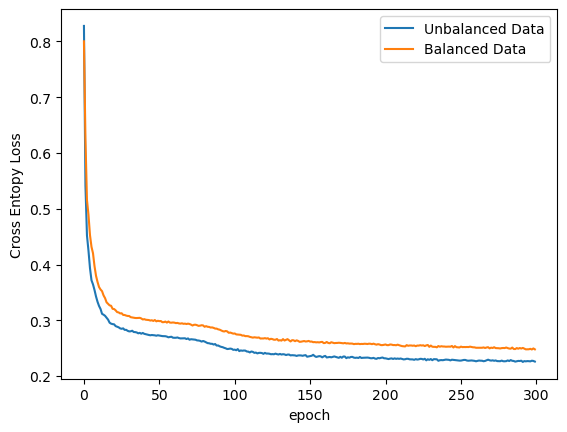

In [ ]:
plt.plot(range(epochs), losses, label='Unbalanced Data')
plt.plot(range(epochs), losses_DataBalanced, label='Balanced Data')
plt.xlabel('epoch')
plt.ylabel('Cross Entopy Loss')
plt.legend()

In [ ]:
with torch.no_grad():
    y_val = model(cat_test, cont_test)
    loss = criterion(y_val, y_test)
print(f'CE Loss: {loss:.8f}')

CE Loss: 0.23187685


In [ ]:
with torch.no_grad():
    y_val_balanced = model(cat_test_balanced, cont_test_balanced)
    loss_balanced = criterion(y_val_balanced, y_test_balanced)
print(f'CE Loss Data Balanced: {loss_balanced:.8f}')

CE Loss Data Balanced: 0.41190434


In [ ]:
rows = 50
correct = 0

print(f'{"Model Output":26} Argmax Y_Test')
for i in range(rows):
    print(f'{str(y_val[i]):26} {y_val[i].argmax():^7}{y_test[i]:^7}')
    if y_val[i].argmax().item() == y_test[i]:
        correct += 1
        
        
print(f'\n{correct} out of {rows} ({100*correct/rows:.2f}%) is correct.')

Model Output               Argmax Y_Test
tensor([ 2.1705, -1.7059])    0      0   
tensor([-2.3512,  1.1474])    1      0   
tensor([ 2.8460, -2.0966])    0      0   
tensor([1.4452, 1.9399])      1      1   
tensor([ 2.2570, -1.3865])    0      0   
tensor([ 1.4929, -1.6453])    0      0   
tensor([ 1.8537, -1.4495])    0      0   
tensor([-2.3182,  1.6633])    1      1   
tensor([ 2.1424, -1.3855])    0      0   
tensor([-1.2888,  0.4188])    1      1   
tensor([ 1.8201, -1.3070])    0      0   
tensor([ 3.1204, -1.9715])    0      0   
tensor([ 1.5663, -1.6057])    0      0   
tensor([-0.7784,  1.0262])    1      1   
tensor([ 1.5180, -2.2631])    0      0   
tensor([-4.5419,  1.1668])    1      1   
tensor([ 2.5091, -1.4234])    0      1   
tensor([ 1.9988, -1.5312])    0      0   
tensor([ 1.9878, -0.2660])    0      0   
tensor([ 1.3951, -1.2067])    0      0   
tensor([-2.0184,  1.7412])    1      1   
tensor([-0.7372,  1.4885])    1      1   
tensor([-2.5979,  0.5615])    1    

In [ ]:
rows = 50
correct = 0

print(f'{"Model Output":26} Argmax Y_Test')
for i in range(rows):
    print(f'{str(y_val_balanced[i]):26} {y_val_balanced[i].argmax():^7}{y_test_balanced[i]:^7}')
    if y_val_balanced[i].argmax().item() == y_test_balanced[i]:
        correct += 1
        
        
print(f'\n{correct} out of {rows} ({100*correct/rows:.2f}%) is correct.')

Model Output               Argmax Y_Test
tensor([ 2.3644, -1.8245])    0      0   
tensor([-2.9041,  1.4629])    1      1   
tensor([-0.5366, -0.3326])    1      1   
tensor([ 0.1776, -0.5943])    0      1   
tensor([ 1.9840, -1.7106])    0      0   
tensor([ 2.6837, -2.3344])    0      0   
tensor([ 2.0598, -1.6309])    0      0   
tensor([ 4.9442, -2.4044])    0      0   
tensor([ 2.9825, -1.9878])    0      0   
tensor([-1.4492,  0.9317])    1      1   
tensor([ 2.8393, -1.6063])    0      0   
tensor([ 3.0110, -1.3374])    0      0   
tensor([-1.1984,  1.9927])    1      1   
tensor([ 0.5355, -0.5351])    0      1   
tensor([ 0.8171, -1.0753])    0      1   
tensor([-2.2978,  1.8213])    1      1   
tensor([ 1.8213, -1.7609])    0      0   
tensor([ 0.5301, -0.0946])    0      1   
tensor([-1.1837,  1.4243])    1      1   
tensor([ 0.2104, -0.1454])    0      1   
tensor([-3.3202,  1.5582])    1      1   
tensor([ 2.3078, -1.9107])    0      0   
tensor([ 2.7618, -1.8962])    0    

In [ ]:
cont_test

tensor([[-73.9528,  40.7834, -73.9560,  40.7822,   1.0000,   0.2935],
        [-73.9840,  40.7550, -73.8852,  40.7727,   1.0000,   8.5440],
        [-73.9495,  40.7849, -73.9342,  40.8017,   2.0000,   2.2643],
        ...,
        [-74.0047,  40.7381, -73.9959,  40.7412,   1.0000,   0.8233],
        [-73.9724,  40.7593, -73.9831,  40.7415,   1.0000,   2.1771],
        [-73.9425,  40.8409, -74.0099,  40.7181,   1.0000,  14.7883]])

In [ ]:
torch.save(model,'models/TaxiModelFareClass_fullmodel.pt')
torch.save(model.state_dict(),'models/TaxiModelFareClass_wb.pt')

In [ ]:
torch.save(model,'models/TaxiModelFareClass_DataBalanced_fullmodel.pt')
torch.save(model.state_dict(),'models/TaxiModelFareClass_DataBalanced_wb.pt')

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd

def haversine_distance(df, lat1, long1, lat2, long2):
    r = 6371
    phi1 = np.radians(df[lat1])
    phi2 = np.radians(df[lat2])
    delta_phi = np.radians(df[lat2]-df[lat1])
    delta_lambda = np.radians(df[long2]-df[long1])
    a = np.sin(delta_phi/2)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda/2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))
    return r * c 

class TabularModel(nn.Module):
    def __init__(self, emb_szs, n_cont, out_sz, layers, p=0.5):
        super().__init__()
        self.embeds = nn.ModuleList([nn.Embedding(ni, nf) for ni,nf in emb_szs])
        self.emb_drop = nn.Dropout(p)
        self.bn_cont = nn.BatchNorm1d(n_cont)
        layerlist = []
        n_emb = sum((nf for ni,nf in emb_szs))
        n_in = n_emb + n_cont
        for i in layers:
            layerlist.append(nn.Linear(n_in,i)) 
            layerlist.append(nn.ReLU(inplace=True))
            layerlist.append(nn.BatchNorm1d(i))
            layerlist.append(nn.Dropout(p))
            n_in = i
        layerlist.append(nn.Linear(layers[-1],out_sz))
        self.layers = nn.Sequential(*layerlist)
    def forward(self, x_cat, x_cont):
        embeddings = []
        for i,e in enumerate(self.embeds):
            embeddings.append(e(x_cat[:,i]))
        x = torch.cat(embeddings, 1)
        x = self.emb_drop(x)
        x_cont = self.bn_cont(x_cont)
        x = torch.cat([x, x_cont], 1)
        return self.layers(x)

In [ ]:
# emb_szs = [(24, 12), (2, 1), (7, 4)]
# model2 = TabularModel(emb_szs, 6, 1, [200,100], p=0.4)
# model2.load_state_dict(torch.load('models/TaxiModelFare_wb.pt'));
# model2.eval() # be sure to run this step!

In [ ]:
df.head(1)

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,dist_km,EDTdate,Hour,AMorPM,Weekday
0,2010-04-19 08:17:56+00:00,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1,2.126312,2010-04-19 04:17:56+00:00,4,am,Mon


In [ ]:
# def test_data(mdl): # pass in the name of the new model
#     # INPUT NEW DATA
#     plat = float(input('What is the pickup latitude?  '))
#     plong = float(input('What is the pickup longitude? '))
#     dlat = float(input('What is the dropoff latitude?  '))
#     dlong = float(input('What is the dropoff longitude? '))
#     psngr = int(input('How many passengers? '))
#     dt = input('What is the pickup date and time?\nFormat as YYYY-MM-DD HH:MM:SS     ')
    
#     # PREPROCESS THE DATA
#     dfx_dict = {'pickup_latitude':plat,'pickup_longitude':plong,'dropoff_latitude':dlat,
#          'dropoff_longitude':dlong,'passenger_count':psngr,'EDTdate':dt}
#     dfx = pd.DataFrame(dfx_dict, index=[0])
#     dfx['dist_km'] = haversine_distance(dfx,'pickup_latitude', 'pickup_longitude',
#                                         'dropoff_latitude', 'dropoff_longitude')
    
#     dfx['EDTdate'] = pd.to_datetime(dfx['EDTdate'])
    
#     # We can skip the .astype(category) step since our fields are small,
#     # and encode them right away
#     dfx['Hour'] = dfx['EDTdate'].dt.hour
#     dfx['AMorPM'] = np.where(dfx['Hour']<12,0,1) 
#     dfx['Weekday'] = dfx['EDTdate'].dt.strftime("%a")
#     dfx['Weekday'] = dfx['Weekday'].replace(['Fri','Mon','Sat','Sun','Thu','Tue','Wed'],
#                                             [0,1,2,3,4,5,6]).astype('int64')
    
#     print(dfx)
    
#     # CREATE CAT AND CONT TENSORS
#     cat_cols = ['Hour', 'AMorPM', 'Weekday']
#     cont_cols = ['pickup_longitude', 'pickup_latitude',
#                  'dropoff_longitude', 'dropoff_latitude',
#                  'passenger_count', 'dist_km']
#     xcats = np.stack([dfx[col].values for col in cat_cols], 1)
#     xcats = torch.tensor(xcats, dtype=torch.int64)
#     xconts = np.stack([dfx[col].values for col in cont_cols], 1)
#     xconts = torch.tensor(xconts, dtype=torch.float)
    
#     print(xcats)
    
#     # PASS NEW DATA THROUGH THE MODEL WITHOUT PERFORMING A BACKPROP
#     with torch.no_grad():
#         z = mdl(xcats, xconts)
#     print(f'\nThe predicted fare amount is ${z.item():.2f}')

In [ ]:
# z = test_data(model2)

In [ ]:
# model_load = torch.load('models/TaxiModelFare_fullmodel.pt')
# model_load.eval()

In [ ]:
# z = test_data(model_load)

In [ ]:
4209.93-4192.48

17.450000000000728

In [ ]:
# model.eval()
# z = test_data(model)